## Estimation of T1

**1. In which quantum state should the qubit initially be prepared ?**

The qubit should be initialized in the state |1> because the coherence time T1 represents the time during which the qubit stay in that state before relaxing to the ground state |0>.

**2. What type of evolution should occur before the measurement ?**

The qubit first needs to be prepared, so we excite it to put it in the |1> state. T1 starts from the moment the qubit is excited in that state.
So when the qubit is prepared, we do nothing to the qubit except waiting until the measurement.

**3. Which quantum observable should be measured ?**

We are looking for a bit-flip error so we need to measure the Z observable.

<0|Z|0> = 1 ; <1|Z|1> = -1  ((coherent because |0> and |1> are Z's eigenvectors)

This enables us to differentiate between the states |0> and |1>

**4. What behavior do you expect when the delay between preparation and measurement increases ?**

The more the delay increases, the more the probability that the qubit relaxes increases. As the time goes, this probability converge to 1. So we need to do multiple measurements. We do the measurement at a certain time t multiple times and we keep the mean of results. Then we increase t and repeat the experiment.

## Estimation of T2

**1. In which quantum state should the qubit initially be prepared ?**

We need to prepare the qubit in the |+> or |-> state (it is maybe simpler to prepare the qubit in the |+> state so we will prepare it in the |+> state), in order to then read the relative phase information between the |0> and |1> states.

**2. What type of evolution should occur before the measurement ?**

Once the qubit is prepared, we know its state and the coherence time T2 starts. Between the initialization and the measurement, we do nothing to the qubit except waiting.

**3. Which quantum observable should be measured ?**

We need to measure a phase-flip error, so we measure the X observable to retrieve an information about the state, so the relative phase. So we need to change from the default Z basis to the X basis by applying the Hadamard gate before measuring.

<+|X|+> = 1 ; <-|X|-> = -1 (coherent because |+> and |-> are X's eigenvectors)

**4. What behavior do you expect when the delay between preparation and measurement increases ?**

The more the delay increases, the more the probability that the relative phase changes (due to environment fluctuation) increases. So we need to do multiple measurements. We do the measurement at a certain time t multiple times and we keep the mean of results. Then we increase t and repeat the experiment.

As the time goes, the system changes from a pure state to a mix of states. So the more we wait, the more the probability that the qubit stays in the pure |+> state converge to 1/2.

# 3 Building a thermal relaxation noise model

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Kraus, SuperOp
from qiskit.visualization import plot_histogram
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator

# Import from Qiskit Aer noise module
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)

In [188]:
nb_qubits = 6

qc = QuantumCircuit(nb_qubits, nb_qubits)

print(qc)


     
q_0: 
     
q_1: 
     
q_2: 
     
q_3: 
     
q_4: 
     
q_5: 
     
c: 6/
     


In [120]:
gate_time = 100e-9

T1s = [116e-6, 98e-6, 132e-6, 90e-6, 146e-6, 83e-6]
T2s = [47e-6, 34e-6, 56e-6, 39e-6, 54e-6, 41e-6]

errors = [ thermal_relaxation_error(t1, t2, gate_time) for t1, t2 in zip(T1s, T2s) ]

noise_thermal = NoiseModel()
for i in range(nb_qubits):
    noise_thermal.add_quantum_error(errors[i], "measure", [i])
    noise_thermal.add_quantum_error(errors[i], "id", [i])

print(noise_thermal)

NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx']
  Instructions with noise: ['measure', 'id']
  Qubits with noise: [0, 1, 2, 3, 4, 5]
  Specific qubit errors: [('measure', (0,)), ('measure', (1,)), ('measure', (2,)), ('measure', (3,)), ('measure', (4,)), ('measure', (5,)), ('id', (0,)), ('id', (1,)), ('id', (2,)), ('id', (3,)), ('id', (4,)), ('id', (5,))]


# 4 Implementing experiments in Qiskit using the Aer simulator

0
{'000001': 1024}
P(1) : 1.0
5
{'000000': 49, '000001': 975}
P(1) : 0.9521484375
10
{'000000': 95, '000001': 929}
P(1) : 0.9072265625
15
{'000000': 120, '000001': 904}
P(1) : 0.8828125
20
{'000000': 156, '000001': 868}
P(1) : 0.84765625
25
{'000000': 197, '000001': 827}
P(1) : 0.8076171875
30
{'000000': 254, '000001': 770}
P(1) : 0.751953125
35
{'000000': 280, '000001': 744}
P(1) : 0.7265625
40
{'000000': 268, '000001': 756}
P(1) : 0.73828125
45
{'000000': 339, '000001': 685}
P(1) : 0.6689453125
50
{'000001': 675, '000000': 349}
P(1) : 0.6591796875
55
{'000000': 373, '000001': 651}
P(1) : 0.6357421875
60
{'000000': 424, '000001': 600}
P(1) : 0.5859375
65
{'000001': 598, '000000': 426}
P(1) : 0.583984375
70
{'000000': 459, '000001': 565}
P(1) : 0.5517578125
75
{'000001': 540, '000000': 484}
P(1) : 0.52734375
80
{'000000': 503, '000001': 521}
P(1) : 0.5087890625
85
{'000000': 531, '000001': 493}
P(1) : 0.4814453125
90
{'000000': 557, '000001': 467}
P(1) : 0.4560546875
95
{'000001': 435,

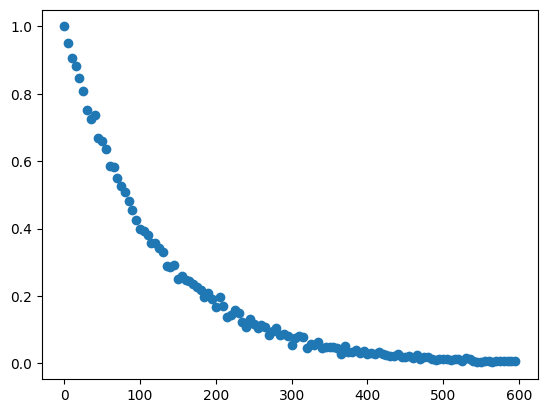

In [123]:
import matplotlib.pyplot as plt

probs = []

qubit = 0

for delay in range(0, 600, 5): # µs
  print(delay)
  qc = QuantumCircuit(nb_qubits, nb_qubits)
  qc.x(qubit)
  for _ in range(10 * delay):
    qc.id(qubit)
  qc.measure(qubit, 0)


  sim = AerSimulator(noise_model=noise_thermal)

  job = sim.run([qc], shots=1024)

  results = job.result()
  counts = results.get_counts()
  print(counts)
  print("P(1) :", counts['000001'] / 1024)

  probs.append(counts['000001'] / 1024)

print(probs)

plt.scatter(range(0, 600, 5), probs)
plt.show()

[1.16441419e+02 9.98472242e-01 7.67941243e-04]


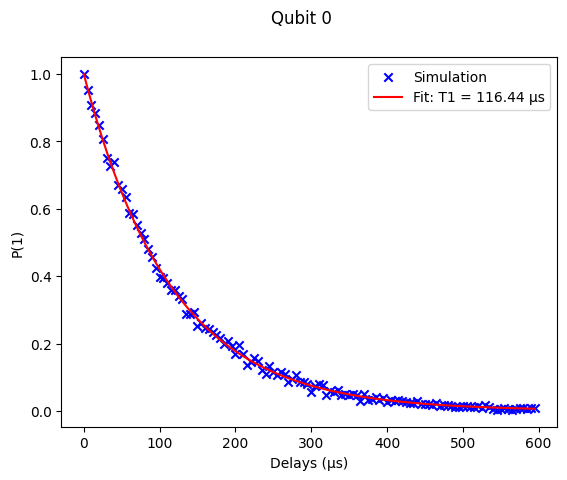

In [146]:
from scipy.optimize import curve_fit

def func(x, T1, A, B):
  return A * np.exp(-x / T1) + B

params, covariance = curve_fit(
  func,
  np.linspace(0, 600, 600 // 5),
  np.array(probs)
)

print(params)

T1 = params[0]

plt.scatter(range(0, 600, 5), probs, marker='x', color='blue', label='Simulation')
plt.plot(range(0, 600, 5), func(np.linspace(0, 600, 600 // 5), *params), color='red', label=f'Fit: T1 = {np.round(T1, 2)} µs')
plt.suptitle("Qubit 0")
plt.xlabel("Delays (µs)")
plt.ylabel("P(1)")
plt.legend()

plt.show()

In [167]:
def T1_experiment(qubit_num = 0):
  print("Calculating T1 ...")

  probs = []

  qubit = qubit_num

  for delay in range(0, 600, 5): # µs
    qc = QuantumCircuit(6, 6)
    qc.x(qubit)
    for _ in range(10 * delay):
      qc.id(qubit)
    qc.measure(qubit, qubit)


    sim = AerSimulator(noise_model=noise_thermal)

    job = sim.run([qc], shots=1024)

    results = job.result()
    counts = results.get_counts()

    label_qubits = ['000001', '000010', '000100', '001000', '010000', '100000']

    try:
      probs.append(counts[label_qubits[qubit]] / 1024)
    except:
      probs.append(0)

  print(probs)

  params, covariance = curve_fit(
    func,
    np.linspace(0, 600, 600 // 5),
    np.array(probs)
  )

  print(params)

  T1 = params[0]

  plt.scatter(range(0, 600, 5), probs, marker='x', color='blue', label='Simulation')
  plt.plot(range(0, 600, 5), func(np.linspace(0, 600, 600 // 5), *params), color='red', label=f'Fit: T1 = {np.round(T1, 2)} µs')
  plt.suptitle(f"Qubit {qubit}")
  plt.xlabel("Delays (µs)")
  plt.ylabel("P(1)")
  plt.legend()

  plt.show()


Calculating T1 ...
[1.0, 0.9580078125, 0.916015625, 0.8818359375, 0.8515625, 0.8056640625, 0.775390625, 0.724609375, 0.6865234375, 0.6630859375, 0.6591796875, 0.625, 0.5869140625, 0.5771484375, 0.5654296875, 0.52734375, 0.5283203125, 0.46484375, 0.474609375, 0.435546875, 0.4267578125, 0.4033203125, 0.3955078125, 0.369140625, 0.373046875, 0.345703125, 0.3056640625, 0.3125, 0.2802734375, 0.283203125, 0.26953125, 0.267578125, 0.216796875, 0.236328125, 0.2451171875, 0.2431640625, 0.2158203125, 0.1982421875, 0.1845703125, 0.17578125, 0.1845703125, 0.1806640625, 0.154296875, 0.158203125, 0.1669921875, 0.1640625, 0.16015625, 0.14453125, 0.1376953125, 0.1298828125, 0.130859375, 0.087890625, 0.103515625, 0.115234375, 0.0966796875, 0.103515625, 0.0849609375, 0.0869140625, 0.095703125, 0.060546875, 0.0791015625, 0.087890625, 0.064453125, 0.0595703125, 0.06640625, 0.0654296875, 0.064453125, 0.0517578125, 0.0517578125, 0.0458984375, 0.0390625, 0.05859375, 0.041015625, 0.033203125, 0.0478515625, 0.0

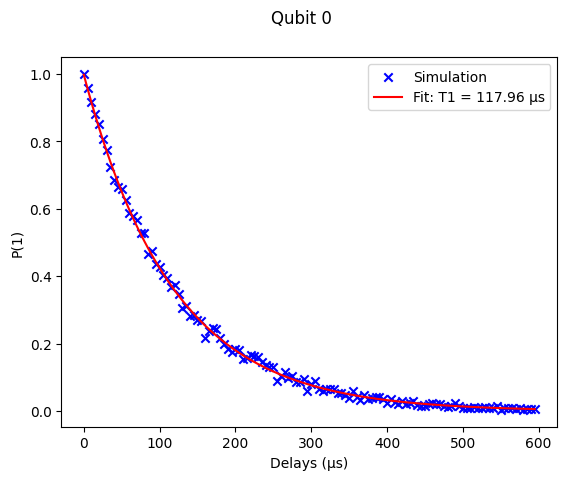

Calculating T1 ...
[1.0, 0.947265625, 0.880859375, 0.8544921875, 0.8359375, 0.783203125, 0.7431640625, 0.6953125, 0.6669921875, 0.6220703125, 0.6025390625, 0.5771484375, 0.5439453125, 0.49609375, 0.466796875, 0.4755859375, 0.4599609375, 0.4296875, 0.4052734375, 0.3857421875, 0.357421875, 0.3251953125, 0.3330078125, 0.287109375, 0.310546875, 0.28515625, 0.265625, 0.2568359375, 0.2265625, 0.2158203125, 0.2314453125, 0.205078125, 0.1826171875, 0.1748046875, 0.138671875, 0.140625, 0.150390625, 0.1552734375, 0.1279296875, 0.1455078125, 0.119140625, 0.1103515625, 0.1240234375, 0.1083984375, 0.099609375, 0.099609375, 0.09375, 0.078125, 0.091796875, 0.078125, 0.078125, 0.0673828125, 0.0751953125, 0.07421875, 0.072265625, 0.0546875, 0.0712890625, 0.060546875, 0.0576171875, 0.0478515625, 0.0400390625, 0.0478515625, 0.0380859375, 0.041015625, 0.0341796875, 0.046875, 0.0419921875, 0.029296875, 0.0205078125, 0.0185546875, 0.029296875, 0.029296875, 0.017578125, 0.017578125, 0.0234375, 0.0205078125, 

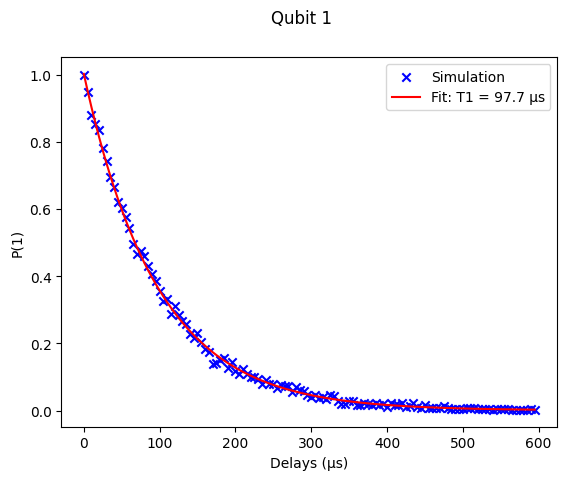

Calculating T1 ...
[1.0, 0.966796875, 0.93359375, 0.8876953125, 0.86328125, 0.830078125, 0.8212890625, 0.76953125, 0.72265625, 0.6962890625, 0.68359375, 0.6650390625, 0.6474609375, 0.5908203125, 0.5791015625, 0.5498046875, 0.5361328125, 0.533203125, 0.5166015625, 0.4951171875, 0.4609375, 0.4501953125, 0.4560546875, 0.4267578125, 0.3935546875, 0.373046875, 0.3779296875, 0.3544921875, 0.3623046875, 0.330078125, 0.3134765625, 0.302734375, 0.2900390625, 0.3232421875, 0.2646484375, 0.2568359375, 0.2578125, 0.2822265625, 0.2158203125, 0.2255859375, 0.2080078125, 0.2060546875, 0.205078125, 0.173828125, 0.1982421875, 0.1845703125, 0.1806640625, 0.1728515625, 0.1708984375, 0.1689453125, 0.15625, 0.1455078125, 0.1376953125, 0.1142578125, 0.12890625, 0.12890625, 0.125, 0.119140625, 0.1142578125, 0.0986328125, 0.103515625, 0.1015625, 0.095703125, 0.09765625, 0.09765625, 0.0869140625, 0.07421875, 0.0830078125, 0.0712890625, 0.072265625, 0.0703125, 0.068359375, 0.076171875, 0.0673828125, 0.064453125

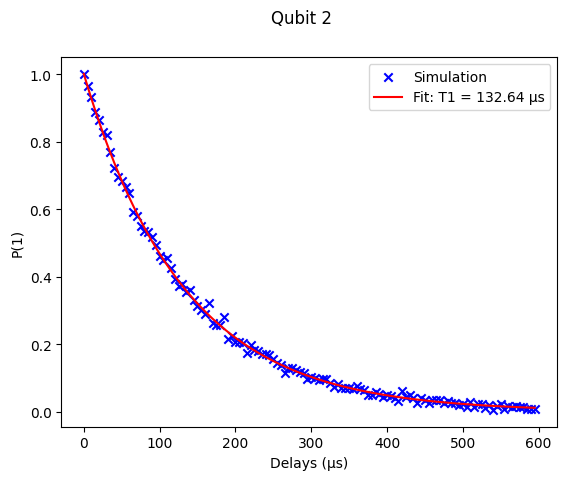

Calculating T1 ...
[1.0, 0.9462890625, 0.8984375, 0.8388671875, 0.78125, 0.7529296875, 0.7373046875, 0.6796875, 0.63671875, 0.599609375, 0.5498046875, 0.5390625, 0.5166015625, 0.4736328125, 0.4609375, 0.4443359375, 0.4013671875, 0.3642578125, 0.3837890625, 0.3349609375, 0.3056640625, 0.3017578125, 0.2666015625, 0.2734375, 0.275390625, 0.26953125, 0.240234375, 0.234375, 0.173828125, 0.21484375, 0.181640625, 0.1689453125, 0.1474609375, 0.1533203125, 0.1416015625, 0.134765625, 0.126953125, 0.1220703125, 0.1328125, 0.0830078125, 0.09765625, 0.1083984375, 0.10546875, 0.0908203125, 0.099609375, 0.07421875, 0.080078125, 0.080078125, 0.05859375, 0.0517578125, 0.0634765625, 0.0751953125, 0.056640625, 0.0673828125, 0.044921875, 0.0400390625, 0.048828125, 0.041015625, 0.0341796875, 0.037109375, 0.0390625, 0.0390625, 0.025390625, 0.0322265625, 0.033203125, 0.0263671875, 0.0263671875, 0.0146484375, 0.03125, 0.0107421875, 0.021484375, 0.0126953125, 0.0205078125, 0.01953125, 0.0146484375, 0.009765625

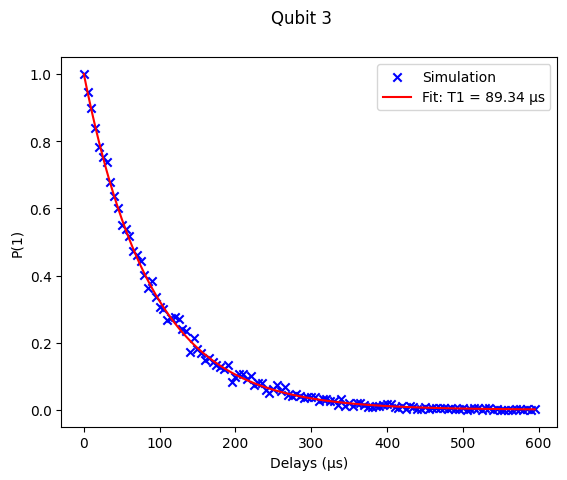

Calculating T1 ...
[0.998046875, 0.966796875, 0.935546875, 0.8935546875, 0.8798828125, 0.82421875, 0.8173828125, 0.8017578125, 0.7509765625, 0.7265625, 0.70703125, 0.6708984375, 0.67578125, 0.626953125, 0.630859375, 0.5986328125, 0.541015625, 0.5615234375, 0.517578125, 0.53515625, 0.4873046875, 0.490234375, 0.4443359375, 0.45703125, 0.4423828125, 0.3935546875, 0.40234375, 0.3720703125, 0.39453125, 0.3525390625, 0.3623046875, 0.3388671875, 0.3359375, 0.306640625, 0.322265625, 0.31640625, 0.275390625, 0.25390625, 0.275390625, 0.263671875, 0.263671875, 0.2392578125, 0.25390625, 0.2451171875, 0.224609375, 0.21484375, 0.2041015625, 0.212890625, 0.2294921875, 0.1904296875, 0.1826171875, 0.169921875, 0.1474609375, 0.1494140625, 0.166015625, 0.1435546875, 0.138671875, 0.1416015625, 0.146484375, 0.1240234375, 0.1416015625, 0.1220703125, 0.1259765625, 0.123046875, 0.0966796875, 0.0966796875, 0.1064453125, 0.083984375, 0.08984375, 0.083984375, 0.09375, 0.080078125, 0.09375, 0.0751953125, 0.078125

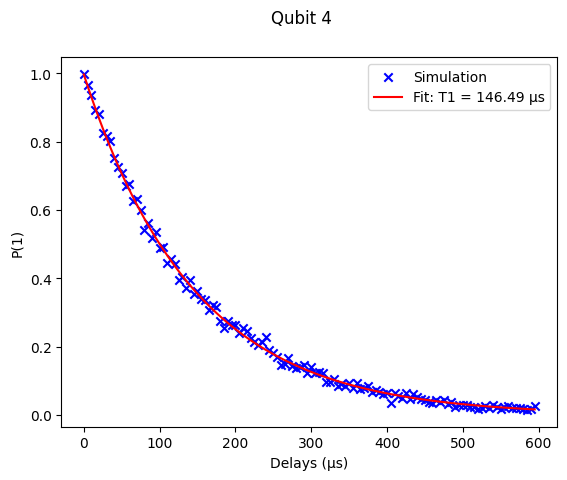

Calculating T1 ...
[0.9990234375, 0.9326171875, 0.8759765625, 0.8212890625, 0.783203125, 0.7177734375, 0.712890625, 0.6669921875, 0.6005859375, 0.5732421875, 0.5771484375, 0.5205078125, 0.5029296875, 0.4521484375, 0.4169921875, 0.4091796875, 0.3828125, 0.3623046875, 0.3271484375, 0.3056640625, 0.30078125, 0.306640625, 0.2587890625, 0.2646484375, 0.2392578125, 0.2373046875, 0.2041015625, 0.17578125, 0.1806640625, 0.169921875, 0.177734375, 0.1767578125, 0.150390625, 0.130859375, 0.1123046875, 0.126953125, 0.123046875, 0.09375, 0.1025390625, 0.1025390625, 0.103515625, 0.078125, 0.078125, 0.080078125, 0.07421875, 0.0673828125, 0.0625, 0.0556640625, 0.0576171875, 0.0625, 0.0537109375, 0.0546875, 0.0302734375, 0.03515625, 0.05078125, 0.029296875, 0.0263671875, 0.0244140625, 0.02734375, 0.03125, 0.03515625, 0.0283203125, 0.017578125, 0.01953125, 0.0234375, 0.021484375, 0.0185546875, 0.017578125, 0.013671875, 0.0166015625, 0.0146484375, 0.017578125, 0.0107421875, 0.009765625, 0.0224609375, 0.0

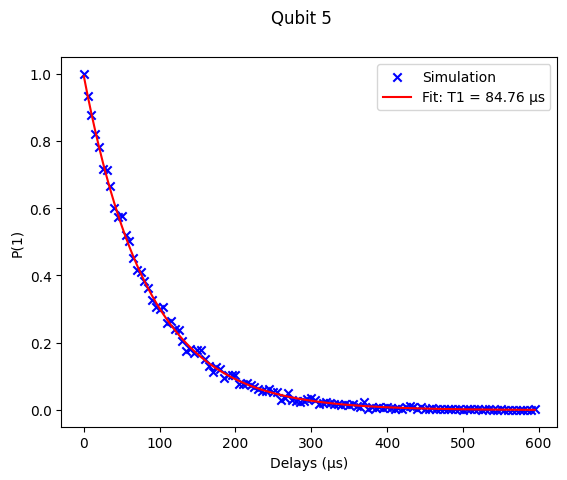

In [170]:
from qiskit.transpiler.passes.analysis import num_qubits
T1_experiment(qubit_num=0)
T1_experiment(qubit_num=1)
T1_experiment(qubit_num=2)
T1_experiment(qubit_num=3)
T1_experiment(qubit_num=4)
T1_experiment(qubit_num=5)

The T1 values obtained using 'curve_fit' are very close to the model data.


It is clear that the longer the measurement time, the higher the probability that the qubit will relax.

# T2 experiment

In [186]:
def func(x, T1, A, B):
  return A * np.exp(-x / T1) + B

def T2_experiment(qubit_num = 0):
  print("Calculating T2 ...")

  probs = []

  qubit = qubit_num

  for delay in range(0, 600, 5): # µs
    qc = QuantumCircuit(6, 6)
    qc.h(qubit)
    for _ in range(10 * delay):
      qc.id(qubit)
    qc.h(qubit)
    qc.measure(qubit, qubit)


    sim = AerSimulator(noise_model=noise_thermal)

    job = sim.run([qc], shots=1024)

    results = job.result()
    counts = results.get_counts()

    try:
      probs.append(counts['000000'] / 1024)
    except:
      probs.append(0)

  print(probs)

  params, covariance = curve_fit(
    func,
    np.linspace(0, 600, 600 // 5),
    np.array(probs)
  )

  print(params)

  T2 = params[0]

  plt.scatter(range(0, 600, 5), probs, marker='x', color='blue', label='Simulation')
  plt.plot(range(0, 600, 5), func(np.linspace(0, 600, 600 // 5), *params), color='red', label=f'Fit: T2 = {np.round(T2, 2)} µs')
  plt.suptitle(f"Qubit {qubit}")
  plt.xlabel("Delays (µs)")
  plt.ylabel("P(0)")
  plt.legend()

  plt.show()


Calculating T2 ...
[1.0, 0.943359375, 0.9072265625, 0.8642578125, 0.830078125, 0.806640625, 0.779296875, 0.71484375, 0.7119140625, 0.697265625, 0.677734375, 0.646484375, 0.6318359375, 0.6181640625, 0.6240234375, 0.603515625, 0.5849609375, 0.5751953125, 0.5927734375, 0.5556640625, 0.572265625, 0.564453125, 0.55078125, 0.5595703125, 0.552734375, 0.541015625, 0.537109375, 0.509765625, 0.5439453125, 0.501953125, 0.5009765625, 0.5029296875, 0.537109375, 0.52734375, 0.529296875, 0.517578125, 0.50390625, 0.4990234375, 0.5322265625, 0.505859375, 0.4990234375, 0.50390625, 0.5029296875, 0.5029296875, 0.5205078125, 0.49609375, 0.5185546875, 0.5205078125, 0.5029296875, 0.4921875, 0.5205078125, 0.5224609375, 0.521484375, 0.4931640625, 0.5224609375, 0.53125, 0.4970703125, 0.498046875, 0.4970703125, 0.478515625, 0.49609375, 0.4990234375, 0.484375, 0.5, 0.5, 0.494140625, 0.490234375, 0.513671875, 0.490234375, 0.509765625, 0.5224609375, 0.4619140625, 0.5244140625, 0.5029296875, 0.4853515625, 0.48925781

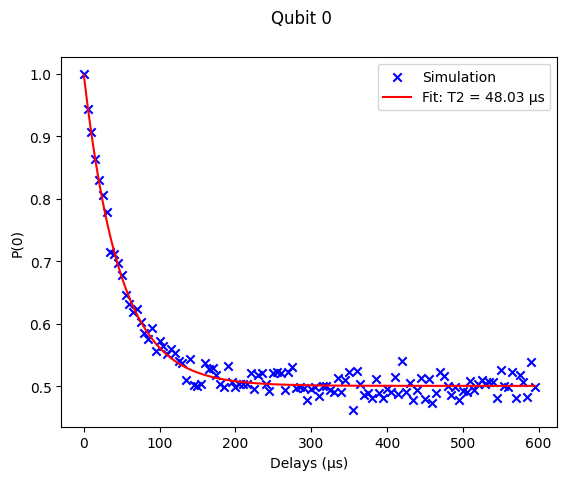

Calculating T2 ...
[1.0, 0.9375, 0.8544921875, 0.8310546875, 0.802734375, 0.7451171875, 0.6982421875, 0.69921875, 0.6904296875, 0.626953125, 0.623046875, 0.576171875, 0.5869140625, 0.578125, 0.57421875, 0.57421875, 0.5537109375, 0.5244140625, 0.5322265625, 0.5341796875, 0.5205078125, 0.52734375, 0.5185546875, 0.5234375, 0.5205078125, 0.509765625, 0.53125, 0.4775390625, 0.5048828125, 0.494140625, 0.521484375, 0.4775390625, 0.5009765625, 0.533203125, 0.4794921875, 0.5048828125, 0.4921875, 0.5048828125, 0.46875, 0.5078125, 0.4853515625, 0.5009765625, 0.474609375, 0.5068359375, 0.486328125, 0.5078125, 0.4833984375, 0.49609375, 0.4912109375, 0.4794921875, 0.5244140625, 0.5205078125, 0.5, 0.5087890625, 0.529296875, 0.49609375, 0.5146484375, 0.50390625, 0.53515625, 0.5048828125, 0.50390625, 0.494140625, 0.4970703125, 0.4990234375, 0.5185546875, 0.484375, 0.4892578125, 0.4892578125, 0.509765625, 0.4873046875, 0.4921875, 0.4912109375, 0.4697265625, 0.509765625, 0.501953125, 0.490234375, 0.51464

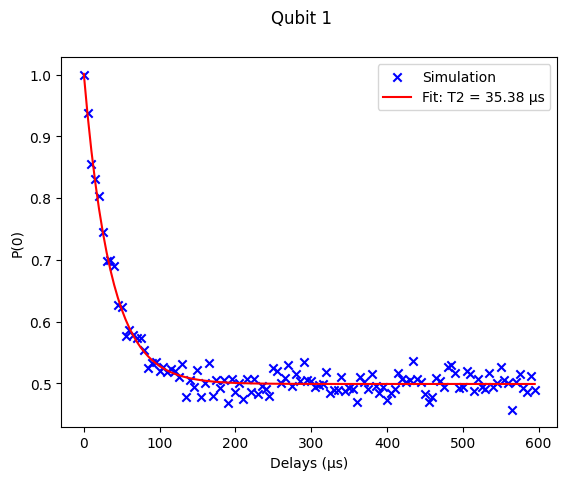

Calculating T2 ...
[1.0, 0.95703125, 0.8984375, 0.8828125, 0.8505859375, 0.814453125, 0.7919921875, 0.77734375, 0.7548828125, 0.73828125, 0.7001953125, 0.6728515625, 0.6689453125, 0.6513671875, 0.6572265625, 0.62890625, 0.62890625, 0.5966796875, 0.56640625, 0.58984375, 0.578125, 0.587890625, 0.5478515625, 0.5625, 0.5810546875, 0.5537109375, 0.5166015625, 0.52734375, 0.5478515625, 0.548828125, 0.541015625, 0.52734375, 0.5478515625, 0.4970703125, 0.53125, 0.533203125, 0.53515625, 0.513671875, 0.505859375, 0.52734375, 0.501953125, 0.5009765625, 0.525390625, 0.505859375, 0.53515625, 0.5146484375, 0.4873046875, 0.5078125, 0.4833984375, 0.4990234375, 0.53125, 0.515625, 0.4990234375, 0.494140625, 0.4990234375, 0.5205078125, 0.4873046875, 0.513671875, 0.513671875, 0.5234375, 0.5, 0.4951171875, 0.50390625, 0.5078125, 0.498046875, 0.5048828125, 0.4765625, 0.5078125, 0.478515625, 0.462890625, 0.4951171875, 0.4853515625, 0.4873046875, 0.47265625, 0.484375, 0.494140625, 0.4794921875, 0.5029296875, 

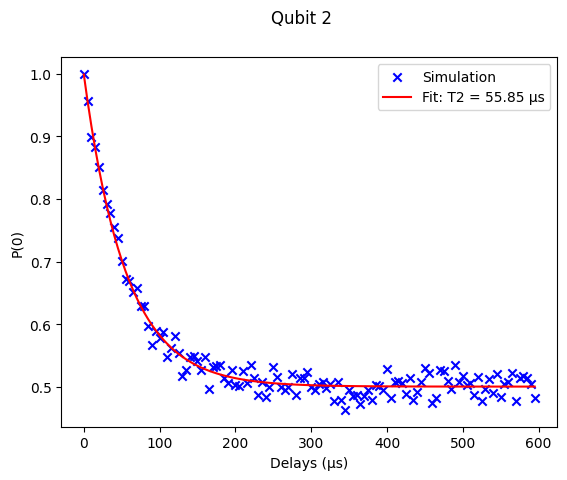

Calculating T2 ...
[1.0, 0.9365234375, 0.8740234375, 0.8369140625, 0.8115234375, 0.7724609375, 0.7412109375, 0.708984375, 0.701171875, 0.66796875, 0.654296875, 0.6064453125, 0.619140625, 0.6328125, 0.578125, 0.546875, 0.5634765625, 0.5244140625, 0.5546875, 0.5390625, 0.552734375, 0.5166015625, 0.529296875, 0.53515625, 0.533203125, 0.529296875, 0.53125, 0.53125, 0.5322265625, 0.5068359375, 0.49609375, 0.4892578125, 0.5048828125, 0.509765625, 0.4833984375, 0.4814453125, 0.4990234375, 0.46484375, 0.50390625, 0.5068359375, 0.4990234375, 0.4970703125, 0.494140625, 0.5029296875, 0.5078125, 0.4638671875, 0.501953125, 0.4951171875, 0.5126953125, 0.5, 0.5107421875, 0.4921875, 0.494140625, 0.494140625, 0.4697265625, 0.513671875, 0.4970703125, 0.4970703125, 0.513671875, 0.5029296875, 0.5185546875, 0.5166015625, 0.478515625, 0.5185546875, 0.5009765625, 0.53515625, 0.47265625, 0.482421875, 0.498046875, 0.50390625, 0.5, 0.5068359375, 0.515625, 0.51171875, 0.4970703125, 0.46875, 0.501953125, 0.467773

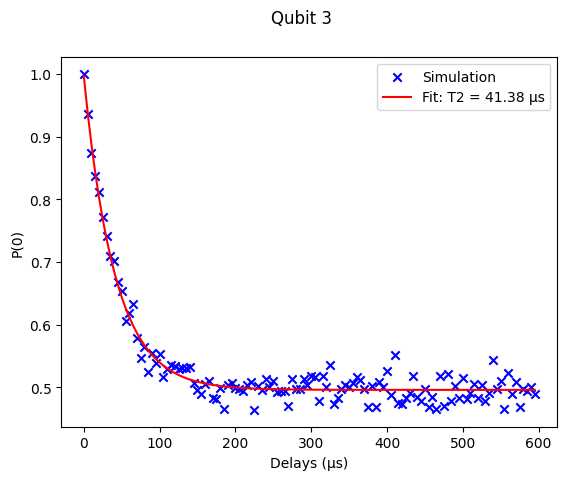

Calculating T2 ...
[1.0, 0.955078125, 0.91796875, 0.8759765625, 0.8642578125, 0.806640625, 0.7685546875, 0.7470703125, 0.759765625, 0.7021484375, 0.689453125, 0.6923828125, 0.6787109375, 0.642578125, 0.6298828125, 0.6376953125, 0.6181640625, 0.5888671875, 0.6005859375, 0.59765625, 0.55078125, 0.5849609375, 0.568359375, 0.58203125, 0.5654296875, 0.546875, 0.53125, 0.5380859375, 0.533203125, 0.5234375, 0.5546875, 0.5419921875, 0.5263671875, 0.53125, 0.5576171875, 0.517578125, 0.5, 0.5107421875, 0.505859375, 0.5166015625, 0.50390625, 0.5224609375, 0.515625, 0.5107421875, 0.5244140625, 0.4892578125, 0.5126953125, 0.5068359375, 0.51953125, 0.4912109375, 0.5283203125, 0.4912109375, 0.4951171875, 0.5029296875, 0.5146484375, 0.4931640625, 0.53515625, 0.5205078125, 0.509765625, 0.4951171875, 0.498046875, 0.5029296875, 0.5078125, 0.513671875, 0.5166015625, 0.509765625, 0.5283203125, 0.5, 0.5, 0.5224609375, 0.4833984375, 0.52734375, 0.5224609375, 0.501953125, 0.48828125, 0.51953125, 0.5029296875,

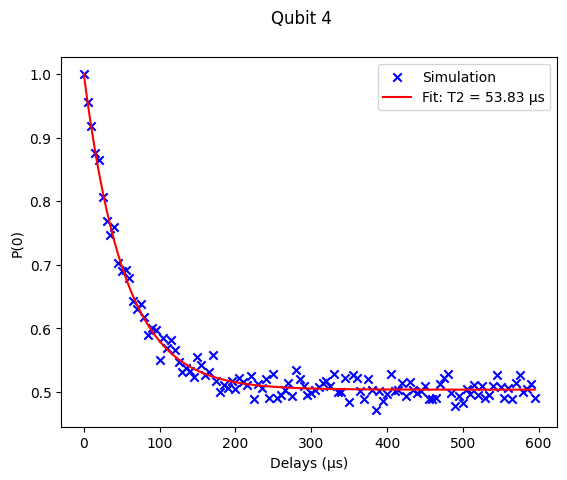

Calculating T2 ...
[1.0, 0.947265625, 0.9150390625, 0.8466796875, 0.796875, 0.755859375, 0.7373046875, 0.716796875, 0.6875, 0.6767578125, 0.64453125, 0.626953125, 0.609375, 0.6123046875, 0.5703125, 0.6015625, 0.54296875, 0.5478515625, 0.556640625, 0.55859375, 0.52734375, 0.5322265625, 0.50390625, 0.5439453125, 0.5185546875, 0.5419921875, 0.4990234375, 0.4931640625, 0.5234375, 0.4970703125, 0.513671875, 0.5146484375, 0.51953125, 0.505859375, 0.501953125, 0.486328125, 0.5146484375, 0.525390625, 0.5419921875, 0.4951171875, 0.517578125, 0.50390625, 0.462890625, 0.5048828125, 0.4931640625, 0.509765625, 0.53125, 0.4990234375, 0.4951171875, 0.544921875, 0.5078125, 0.4765625, 0.50390625, 0.4921875, 0.513671875, 0.51171875, 0.48828125, 0.501953125, 0.5029296875, 0.498046875, 0.5068359375, 0.484375, 0.4794921875, 0.4794921875, 0.4990234375, 0.5107421875, 0.51171875, 0.5185546875, 0.505859375, 0.5078125, 0.4814453125, 0.50390625, 0.4814453125, 0.4912109375, 0.48046875, 0.5205078125, 0.5400390625,

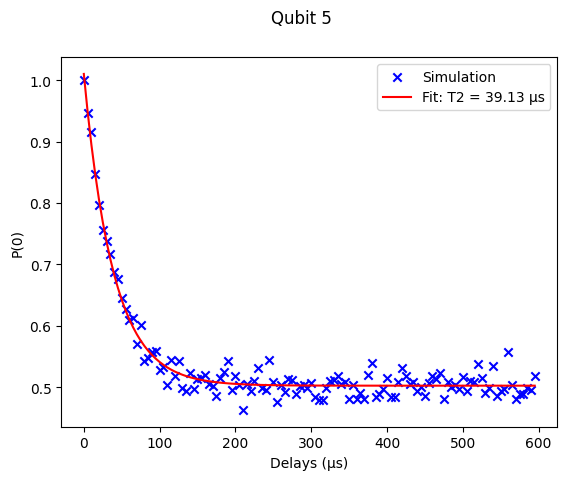

In [187]:
T2_experiment(qubit_num=0)
T2_experiment(qubit_num=1)
T2_experiment(qubit_num=2)
T2_experiment(qubit_num=3)
T2_experiment(qubit_num=4)
T2_experiment(qubit_num=5)

The T2 values obtained using 'curve_fit' are very close to the model data.

It is clear that the longer the measurement time, the more ‘impure’ the system becomes (it is a mixture of states). Consequently, the probability converges towards 1/2.